In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import  numpy as np

sns.set_style('darkgrid')

/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [3]:
df = pd.read_excel('Wk_01_Supply_Chain_Dataset.xlsx', sheet_name='Supply_Chain_Logs', header=4)
df.head()

,TransactionID,Date,Product_Name,Category,Supplier,Units_Ordered,Units_Received,Units_Sold,Stock_On_Hand,Lead_Time_Days,Stockout_Flag,Region
0,SCL00001,2024-05-04,Bread 400g,Bakery,Bidco Africa,138,122,30,139,14,No,Ngong Road
1,SCL00002,2024-01-27,Chicken 1kg,Meat,Twiga Foods,255,249,41,223,8,No,Westlands
2,SCL00003,2023-02-20,Sugar 2kg,Grocery,Bidco Africa,363,362,313,114,4,No,Eastleigh
3,SCL00004,2023-07-13,Eggs Tray 30,Eggs,Twiga Foods,63,60,55,105,14,No,Kiambu
4,SCL00005,2024-06-16,Pampers Size 4,Baby,Export Trading Group,65,56,33,92,8,No,Karen


In [4]:
df.shape

(4500, 12)

In [5]:
df.dtypes

TransactionID             object
Date              datetime64[ns]
Product_Name              object
Category                  object
Supplier                  object
Units_Ordered              int64
Units_Received             int64
Units_Sold                 int64
Stock_On_Hand              int64
Lead_Time_Days             int64
Stockout_Flag             object
Region                    object
dtype: object

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   TransactionID   4500 non-null   object        
 1   Date            4500 non-null   datetime64[ns]
 2   Product_Name    4500 non-null   object        
 3   Category        4500 non-null   object        
 4   Supplier        4500 non-null   object        
 5   Units_Ordered   4500 non-null   int64         
 6   Units_Received  4500 non-null   int64         
 7   Units_Sold      4500 non-null   int64         
 8   Stock_On_Hand   4500 non-null   int64         
 9   Lead_Time_Days  4500 non-null   int64         
 10  Stockout_Flag   4500 non-null   object        
 11  Region          4500 non-null   object        
dtypes: datetime64[ns](1), int64(5), object(6)
memory usage: 422.0+ KB


In [8]:
df['Date'] = pd.to_datetime(df['Date'])

In [9]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month_name()
df['Quater'] = df['Date'].dt.quarter
df['DayOfWeek'] = df['Date'].dt.day_name()

df.head()

,TransactionID,Date,Product_Name,Category,Supplier,Units_Ordered,Units_Received,Units_Sold,Stock_On_Hand,Lead_Time_Days,Stockout_Flag,Region,Year,Month,Quater,DayOfWeek
0,SCL00001,2024-05-04,Bread 400g,Bakery,Bidco Africa,138,122,30,139,14,No,Ngong Road,2024,May,2,Saturday
1,SCL00002,2024-01-27,Chicken 1kg,Meat,Twiga Foods,255,249,41,223,8,No,Westlands,2024,January,1,Saturday
2,SCL00003,2023-02-20,Sugar 2kg,Grocery,Bidco Africa,363,362,313,114,4,No,Eastleigh,2023,February,1,Monday
3,SCL00004,2023-07-13,Eggs Tray 30,Eggs,Twiga Foods,63,60,55,105,14,No,Kiambu,2023,July,3,Thursday
4,SCL00005,2024-06-16,Pampers Size 4,Baby,Export Trading Group,65,56,33,92,8,No,Karen,2024,June,2,Sunday


In [13]:
missing_per_column = df.isnull().sum()
missing_percentage_per_column = (missing_per_column/len(df)) * 100

missing_df = pd.DataFrame({
    "missing_per_column": missing_per_column,
    "missing_percentage_per_column" : missing_percentage_per_column
})

missing_df

,missing_per_column,missing_percentage_per_column
TransactionID,0,0.0
Date,0,0.0
Product_Name,0,0.0
Category,0,0.0
Supplier,0,0.0
Units_Ordered,0,0.0
Units_Received,0,0.0
Units_Sold,0,0.0
Stock_On_Hand,0,0.0
Lead_Time_Days,0,0.0


In [21]:
inconsistencies_count = 0
inconsistencies = []
for index, row in df.iterrows():
    if row["Units_Received"] > row["Units_Ordered"]:
        inconsistencies_count += 1
        inconsistencies.append({row})

print("Total inconsistencies: ", inconsistencies_count)
inconsistencies_df = pd.DataFrame(inconsistencies)
inconsistencies_df.head()


Total inconsistencies:  0


""


In [18]:
total_duplicates = df.duplicated("TransactionID").sum()
print("Total duplicates: ", total_duplicates)

Total duplicates:  0


In [24]:
data_quality_score = (1- (total_duplicates + inconsistencies_count + missing_per_column.sum()) /(df.shape[0] * df.shape[1])) * 100
print("Data Quality Score: ", data_quality_score)

Data Quality Score:  100.0


In [29]:
stock_out_rate = df.groupby('Category')['Stockout_Flag'].apply(lambda x: (x== 'Yes').mean()).sort_values(ascending=False)
print(stock_out_rate)

Category
Dairy            0.066901
Baby             0.048951
Noodles          0.046667
Produce          0.045302
Bakery           0.042071
Personal Care    0.035088
Detergent        0.034965
Grocery          0.033557
Eggs             0.032028
Oil              0.028169
Meat             0.027190
Tea              0.024169
Flour            0.023952
Grain            0.020339
Name: Stockout_Flag, dtype: float64


In [32]:
lead_time = df.groupby('Supplier')['Lead_Time_Days'].mean()
print(lead_time)

Supplier
Bakeries Ltd            11.779621
Bidco Africa            11.211581
Brookside Dairy         11.819172
Chandaria Industries    11.784355
Export Trading Group    11.666667
KFC Supply              11.484513
KWAL                    11.605701
Pembe Flour             11.220000
Twiga Foods             11.415966
Unga Group              11.432558
Name: Lead_Time_Days, dtype: float64


<AxesSubplot:title={'center':'Average Lead Time By Supplier'}, ylabel='Supplier'>

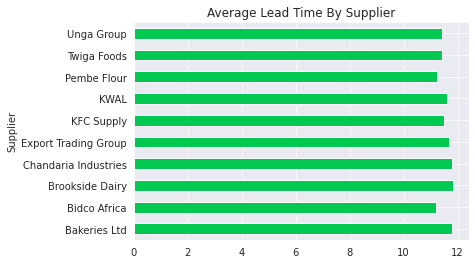

In [33]:
lead_time.plot(kind='barh',title='Average Lead Time By Supplier', color='#00C851')

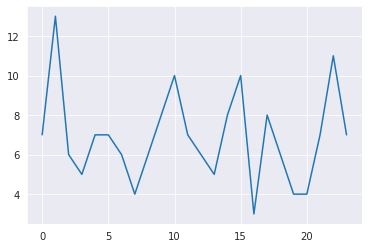

In [34]:
monthly_stockouts = df[df['Stockout_Flag'] == 'Yes'].groupby(['Year','Month']).size().reset_index(name ='Count')
plt.plot(monthly_stockouts['Count'])

In [37]:
region_stockouts = df.groupby('Region')['Stockout_Flag'].apply(lambda x: (x == 'Yes').sum()).sort_values(ascending=False)
print(region_stockouts)

Region
Westlands       28
Thika Road      26
Mombasa Road    25
Ngong Road      23
Kiambu          22
Karen           21
Eastleigh       20
Name: Stockout_Flag, dtype: int64


<AxesSubplot:title={'center':'Region Stockouts'}, xlabel='Region'>

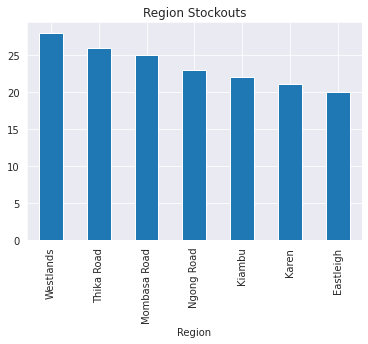

In [42]:
region_stockouts.plot(title = 'Region Stockouts', kind='bar')

In [39]:
df['Fulfillment_rate'] = df['Units_Received']/df['Units_Ordered']
fullfilment = df.groupby('Supplier')['Fulfillment_rate'].mean().sort_values()

print(fullfilment)

Supplier
Export Trading Group    0.923672
Twiga Foods             0.924377
Brookside Dairy         0.924750
Bakeries Ltd            0.925304
Pembe Flour             0.926632
Unga Group              0.926980
KFC Supply              0.927326
Bidco Africa            0.927369
Chandaria Industries    0.928402
KWAL                    0.928956
Name: Fulfillment_rate, dtype: float64


<AxesSubplot:title={'center':'Supplier Fulfillment Rate'}, xlabel='Supplier'>

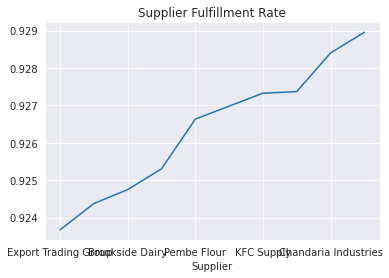

In [50]:
fullfilment.plot(title='Supplier Fulfillment Rate', kind='line')